In [26]:
import os
import xarray as xr
import numpy as np
from cdo import Cdo
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import tempfile
import logging

from eoceneNEMO import EoceneNEMO

cdo = Cdo()
loggy = logging.getLogger(__name__)

In [27]:
eocene = EoceneNEMO(
    herold_folder="/lus/h2resw01/hpcperm/ecme3497/herold-et-al-2014/Supp",
    input_folder="/lus/h2resw01/hpcperm/ecme3497/ece4-data-v9/ece-4-inidata_4.1.9",
    output_folder="/lus/h2resw01/hpcperm/ecme3497/ece4-data-v9-paleo/ece-4-inidata_4.1.9"
)

grid= "r720x360"

In [28]:
m2_varname="eo_tidal_dissipation"
hcri_value=500.0
cleanup=True

herold_file_orig = os.path.join(eocene.herold_folder, "Green_Huber_eocene_tidal_dissipation_1x1.nc")
herold_file_remap = os.path.join(eocene.herold_folder, "Green_Huber_eocene_tidal_dissipation_r720x360.nc")
herold_bath_orig = os.path.join(eocene.herold_folder, "herold_etal_eocene_topo_1x1.nc")
herold_bath_remap = os.path.join(eocene.herold_folder, "herold_etal_eocene_topo_1x1_r720x360.nc")
zdfiwm_file = os.path.join(eocene.input_folder, "nemo/initial/zdfiwm_forcing_r720x360.nc")
output_file = os.path.join(eocene.output_folder, "nemo/initial/zdfiwm_forcing_r720x360.nc")
runoff = os.path.join(eocene.input_folder, "nemo/climatology/runoff_DaiTrenberth_PALEORCA2.nc")
runoff_output = os.path.join(eocene.output_folder, "nemo/climatology/runoff_DaiTrenberth_PALEORCA2.nc")

In [29]:
if cleanup and os.path.exists(output_file):
    os.remove(output_file)
    loggy.info("Cleaning file: %s", output_file)

herold_file_remap = eocene.cdo.remapcon(eocene.grid, input=herold_file_orig)
herold_bath_remap = eocene.cdo.remapcon(eocene.grid, input=herold_bath_orig)

ds_m2 = xr.open_dataset(herold_file_remap)
ds_bt = xr.open_dataset (herold_bath_remap)
ds_pd = xr.open_dataset(zdfiwm_file)

m2 = ds_m2[m2_varname]

In [30]:
# Interpolate topo onto the ds_pd grid
topo_interp = ds_bt["topo"].interp(
    lat=ds_pd.latitude,
    lon=ds_pd.longitude,
    method="linear"
)

In [31]:
ocean_topo = topo_interp.where(topo_interp < 0.0)

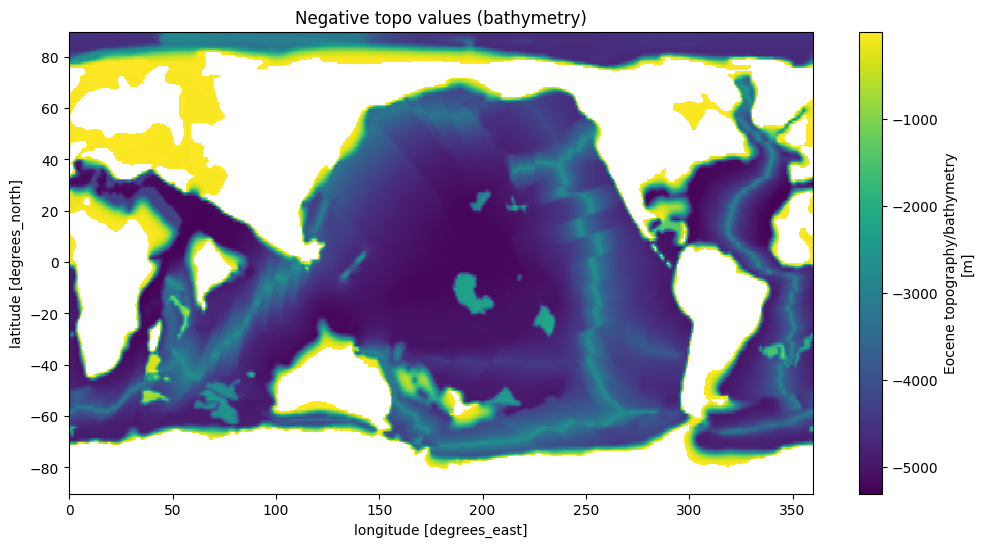

In [32]:
import matplotlib.pyplot as plt

ocean_topo.plot(figsize=(12, 6))
plt.title("Negative topo values (bathymetry)")
plt.show()

In [33]:
# make a copy of present-day file
ds_out = ds_pd.copy(deep=True)

# inject M2 into power_cri (1/3 only)
ds_out['power_cri'][:] = (1.0 / 3.0) * m2.values

# modify bathymetry
ds_out['bathymetry'][:] = ocean_topo

# zero in other energy reservoirs
ds_out['power_nsq'][:] = 0.0
ds_out['power_sho'][:] = 0.0
ds_out['power_bot'][:] = 0.0

# set vertical length scales
ds_out['scale_cri'][:] = hcri_value
ds_out['scale_bot'][:] = 0.0   # unused if power_bot = 0

# convert NaN into zeroes
ds_out = ds_out.fillna(0)

# write output file
os.makedirs(os.path.join(eocene.output_folder, "nemo/initial"), exist_ok=True)
ds_out.to_netcdf(output_file)
loggy.info("Written NEMO 4.2 tidal file: %s", output_file)

ds_m2.close()
ds_pd.close()

In [34]:
print (ds_out)

<xarray.Dataset> Size: 15MB
Dimensions:     (latitude: 360, longitude: 720)
Coordinates:
  * latitude    (latitude) float64 3kB -90.0 -89.5 -89.0 ... 88.5 89.0 89.5
  * longitude   (longitude) float64 6kB 0.0 0.5 1.0 1.5 ... 358.5 359.0 359.5
Data variables:
    power_bot   (latitude, longitude) float64 2MB 0.0 0.0 0.0 ... 0.0 0.0 0.0
    power_cri   (latitude, longitude) float64 2MB 0.0 0.0 0.0 ... 0.0 0.0 0.0
    power_nsq   (latitude, longitude) float64 2MB 0.0 0.0 0.0 ... 0.0 0.0 0.0
    power_sho   (latitude, longitude) float64 2MB 0.0 0.0 0.0 ... 0.0 0.0 0.0
    scale_cri   (latitude, longitude) float64 2MB 500.0 500.0 ... 500.0 500.0
    scale_bot   (latitude, longitude) float64 2MB 0.0 0.0 0.0 ... 0.0 0.0 0.0
    bathymetry  (latitude, longitude) float64 2MB 0.0 0.0 ... -4.528e+03
Attributes:
    CDI:                       Climate Data Interface version 1.9.8 (https://...
    Conventions:               CF-1.6
    history:                   Sun Aug 04 00:59:55 2024: cdo -L -P 16

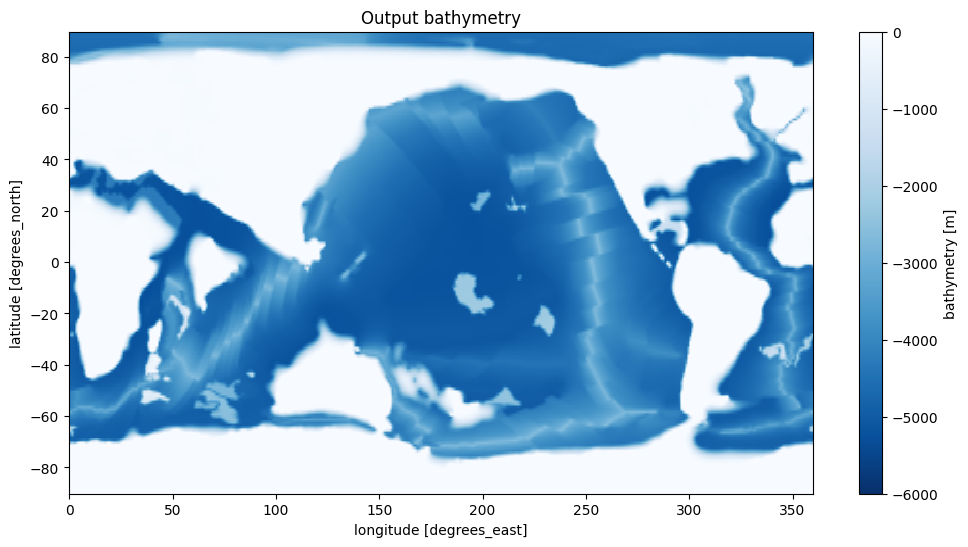

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
ds_out["bathymetry"].plot(cmap="Blues_r", vmin=-6000, vmax=0)
plt.title("Output bathymetry")
plt.show()

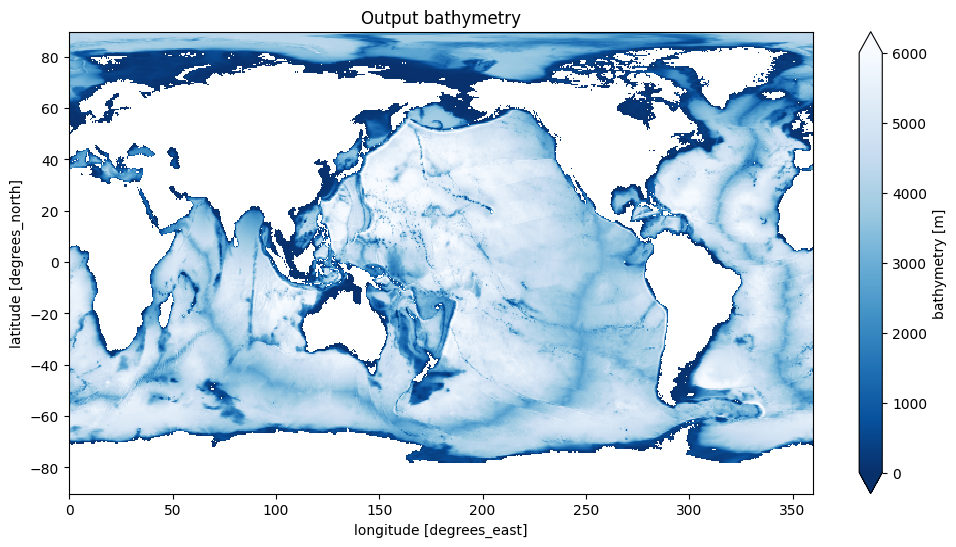

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
ds_pd["bathymetry"].plot(cmap="Blues_r", vmin=6000, vmax=0)
plt.title("Output bathymetry")
plt.show()

In [37]:
ds_rnf = xr.open_dataset(runoff)

In [38]:
print (ds_rnf)

<xarray.Dataset> Size: 4MB
Dimensions:   (y: 174, x: 180, bnds: 4, time: 12)
Coordinates:
    lon       (y, x) float64 251kB ...
    lat       (y, x) float64 251kB ...
  * time      (time) float64 96B 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0
Dimensions without coordinates: y, x, bnds
Data variables:
    lon_bnds  (y, x, bnds) float64 1MB ...
    lat_bnds  (y, x, bnds) float64 1MB ...
    nav_lat   (y, x) float32 125kB ...
    nav_lon   (y, x) float32 125kB ...
    socoefr   (y, x) float32 125kB ...
    sorunoff  (time, y, x) float32 2MB ...
Attributes: (12/18)
    CDI:                        Climate Data Interface version 2.5.1 (https:/...
    Conventions:                CF-1.6
    title:                      global runoff projected on eORCA1 grid
    description1:               north of 60 south : Dai_Trenberth Continental...
    description2:               south of 60 south : Depoorter Freshwater Disc...
    description3:               Merino I. Freshwater flux from Iceberg me

In [39]:
ds_out = ds_rnf.copy(deep=True)
ds_out['socoefr'][:] = 0.0
ds_out['sorunoff'][:] = 0.0

In [40]:
# convert NaN into zeroes
ds_out = ds_out.fillna(0)

# write output file
os.makedirs(os.path.join(eocene.output_folder, "nemo/initial"), exist_ok=True)
ds_out.to_netcdf(runoff_output)
loggy.info("Written NEMO 4.2 runoff file: %s", output_file)

ds_rnf.close()